In [1]:
# imports

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer


In [2]:
# paths

ORIGINAL_DATA_PATH = Path("data/raw/data_core.csv")
NEW_DATA_PATH = Path("data/raw/new_data_core.csv")

ORIGINAL_OUTPUT_DIR = Path("results/outputs/original")
NEW_OUTPUT_DIR = Path("results/outputs/new")

ORIGINAL_EDA_DIR = Path("results/eda_visualizations/original")
NEW_EDA_DIR = Path("results/eda_visualizations/new")

for path in [
    ORIGINAL_OUTPUT_DIR,
    NEW_OUTPUT_DIR,
    ORIGINAL_EDA_DIR,
    NEW_EDA_DIR,
]:
    path.mkdir(parents=True, exist_ok=True)


In [3]:
# load data

original_df = pd.read_csv(ORIGINAL_DATA_PATH)
new_df = pd.read_csv(NEW_DATA_PATH)

new_df = new_df.drop(columns=["Link"], errors="ignore")

print("Original dataset:", original_df.shape)
print("New dataset:", new_df.shape)

print("\nOriginal columns:")
print(original_df.columns.tolist())

print("\nNew columns:")
print(new_df.columns.tolist())


Original dataset: (8000, 9)
New dataset: (4513, 10)

Original columns:
['Temparature', 'Humidity', 'Moisture', 'Soil Type', 'Crop Type', 'Nitrogen', 'Potassium', 'Phosphorous', 'Fertilizer Name']

New columns:
['District_Name', 'Soil_color', 'Nitrogen', 'Phosphorus', 'Potassium', 'pH', 'Rainfall', 'Temperature', 'Crop', 'Fertilizer']


In [4]:
# dataset setup

original_target = "Fertilizer Name"
new_target = "Fertilizer"

original_features = [
    "Temparature",
    "Humidity",
    "Moisture",
    "Soil Type",
    "Crop Type",
    "Nitrogen",
    "Potassium",
    "Phosphorous",
]

new_features = [
    "District_Name",
    "Soil_color",
    "Nitrogen",
    "Phosphorus",
    "Potassium",
    "pH",
    "Rainfall",
    "Temperature",
    "Crop",
]


In [5]:
# validation

def validate_dataset(name, df, target):
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Target classes:", df[target].nunique())

    print("\nTarget distribution:")
    print(
        (df[target].value_counts(normalize=True) * 100)
        .round(2)
        .to_string()
    )

    print("\nNumeric ranges:")
    for col in df.select_dtypes(include="number").columns:
        print(
            f"{col}: "
            f"{df[col].min()} - {df[col].max()} "
            f"(mean {df[col].mean():.2f})"
        )

validate_dataset("Original dataset", original_df, original_target)
validate_dataset("New dataset", new_df, new_target)



Original dataset
Shape: (8000, 9)
Missing values: 0
Duplicate rows: 0
Target classes: 7

Target distribution:
Fertilizer Name
14-35-14    14.85
Urea        14.62
DAP         14.59
10-26-26    14.10
17-17-17    14.05
28-28       14.00
20-20       13.79

Numeric ranges:
Temparature: 20.0 - 40.0 (mean 30.34)
Humidity: 40.02 - 80.0 (mean 59.21)
Moisture: 20.0 - 70.0 (mean 43.58)
Nitrogen: 0 - 46 (mean 18.43)
Potassium: 0 - 23 (mean 3.92)
Phosphorous: 0 - 46 (mean 18.51)

New dataset
Shape: (4513, 10)
Missing values: 0
Duplicate rows: 0
Target classes: 19

Target distribution:
Fertilizer
Urea                      30.22
DAP                       14.78
MOP                       12.65
19:19:19 NPK              10.64
SSP                        9.24
Magnesium Sulphate         4.76
10:26:26 NPK               3.46
50:26:26 NPK               2.75
Chilated Micronutrient     2.39
12:32:16 NPK               2.35
Ferrous Sulphate           1.51
13:32:26 NPK               1.46
Ammonium Sulphate        

In [6]:
# conflicting combinations

def check_conflicts(name, df, features, target):
    repeated = df.duplicated(
        subset=features,
        keep=False
    ).sum()

    conflicts = (
        df.groupby(features)[target]
        .nunique()
        .gt(1)
        .sum()
    )

    print(f"\n{name}")
    print("Repeated feature rows:", repeated)
    print("Conflicting combinations:", conflicts)

check_conflicts(
    "Original dataset",
    original_df,
    original_features,
    original_target
)

check_conflicts(
    "New dataset",
    new_df,
    new_features,
    new_target
)



Original dataset
Repeated feature rows: 0
Conflicting combinations: 0

New dataset
Repeated feature rows: 6
Conflicting combinations: 3


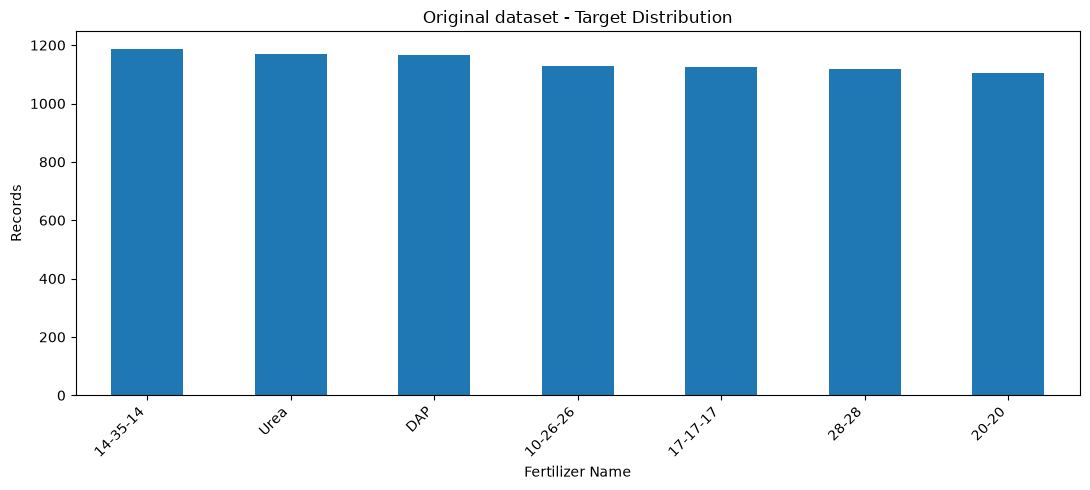

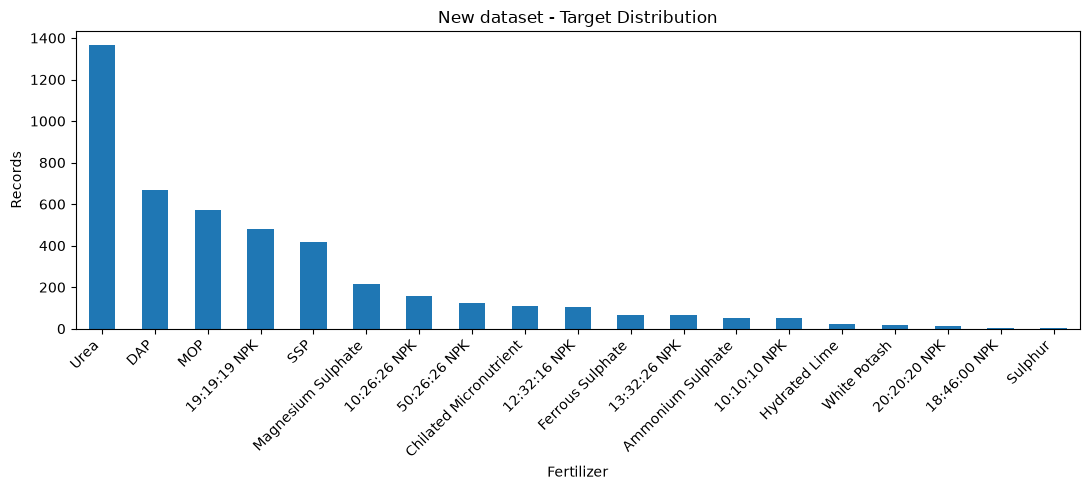

In [7]:
# target distributions

for name, df, target, out_dir in [
    ("Original dataset", original_df, original_target, ORIGINAL_EDA_DIR),
    ("New dataset", new_df, new_target, NEW_EDA_DIR),
]:
    counts = df[target].value_counts()

    plt.figure(figsize=(11, 5))
    counts.plot(kind="bar")
    plt.title(f"{name} - Target Distribution")
    plt.xlabel(target)
    plt.ylabel("Records")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(out_dir / "target_distribution.png", dpi=150)
    plt.show()


In [8]:
# train-test split

X_original = original_df[original_features].copy()
y_original = original_df[original_target].copy()

X_new = new_df[new_features].copy()
y_new = new_df[new_target].copy()

X_train_original, X_test_original, y_train_original, y_test_original = train_test_split(
    X_original,
    y_original,
    test_size=0.20,
    random_state=42,
    stratify=y_original
)

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new,
    y_new,
    test_size=0.20,
    random_state=42,
    stratify=y_new
)

print("Original dataset")
print("Train:", X_train_original.shape)
print("Test:", X_test_original.shape)

print("\nNew dataset")
print("Train:", X_train_new.shape)
print("Test:", X_test_new.shape)


Original dataset
Train: (6400, 8)
Test: (1600, 8)

New dataset
Train: (3610, 9)
Test: (903, 9)


In [9]:
# outlier helpers

original_numeric = [
    "Temparature",
    "Humidity",
    "Moisture",
    "Nitrogen",
    "Potassium",
    "Phosphorous",
]

new_numeric = [
    "Nitrogen",
    "Phosphorus",
    "Potassium",
    "pH",
    "Rainfall",
    "Temperature",
]

def fit_iqr_bounds(X, columns):
    bounds = {}

    for col in columns:
        q1 = X[col].quantile(0.25)
        q3 = X[col].quantile(0.75)
        iqr = q3 - q1

        bounds[col] = (
            q1 - 1.5 * iqr,
            q3 + 1.5 * iqr
        )

    return bounds

def outlier_summary(X, bounds):
    rows = []

    for col, (lower, upper) in bounds.items():
        count = ((X[col] < lower) | (X[col] > upper)).sum()

        rows.append({
            "Feature": col,
            "Lower": lower,
            "Upper": upper,
            "Outliers": int(count)
        })

    return pd.DataFrame(rows)

def cap_outliers(X, bounds):
    X = X.copy()

    for col, (lower, upper) in bounds.items():
        X[col] = X[col].clip(
            lower=lower,
            upper=upper
        )

    return X


In [10]:
# outlier treatment

original_bounds = fit_iqr_bounds(
    X_train_original,
    original_numeric
)

new_bounds = fit_iqr_bounds(
    X_train_new,
    new_numeric
)

original_outliers = outlier_summary(
    X_train_original,
    original_bounds
)

new_outliers = outlier_summary(
    X_train_new,
    new_bounds
)

print("Original dataset")
display(original_outliers)

print("New dataset")
display(new_outliers)

original_outliers.to_csv(
    ORIGINAL_OUTPUT_DIR / "outlier_summary.csv",
    index=False
)

new_outliers.to_csv(
    NEW_OUTPUT_DIR / "outlier_summary.csv",
    index=False
)

X_train_original_clean = cap_outliers(
    X_train_original,
    original_bounds
)

X_test_original_clean = cap_outliers(
    X_test_original,
    original_bounds
)

X_train_new_clean = cap_outliers(
    X_train_new,
    new_bounds
)

X_test_new_clean = cap_outliers(
    X_test_new,
    new_bounds
)

print("Outlier treatment completed.")


Original dataset


,Feature,Lower,Upper,Outliers
0,Temparature,17.49000,43.09000,0
1,Humidity,36.07375,82.40375,0
2,Moisture,5.42750,81.34750,0
3,Nitrogen,-16.50000,51.50000,0
4,Potassium,-7.50000,12.50000,732
5,Phosphorous,-25.00000,63.00000,0


New dataset


,Feature,Lower,Upper,Outliers
0,Nitrogen,-25.0,215.0,0
1,Phosphorus,2.5,102.5,0
2,Potassium,-12.5,127.5,395
3,pH,4.5,8.5,0
4,Rainfall,0.0,1600.0,7
5,Temperature,5.0,45.0,0


Outlier treatment completed.


In [11]:
# feature engineering

def add_engineered_features(X, phosphorus_col):
    X = X.copy()

    X["Total_Nutrients"] = (
        X["Nitrogen"]
        + X[phosphorus_col]
        + X["Potassium"]
    )

    X["NPK_Imbalance"] = (
        X[["Nitrogen", phosphorus_col, "Potassium"]].max(axis=1)
        - X[["Nitrogen", phosphorus_col, "Potassium"]].min(axis=1)
    )

    return X

X_train_original_work = add_engineered_features(
    X_train_original_clean,
    "Phosphorous"
)

X_test_original_work = add_engineered_features(
    X_test_original_clean,
    "Phosphorous"
)

X_train_new_work = add_engineered_features(
    X_train_new_clean,
    "Phosphorus"
)

X_test_new_work = add_engineered_features(
    X_test_new_clean,
    "Phosphorus"
)

print("Original:", X_train_original_work.shape)
print("New:", X_train_new_work.shape)


Original: (6400, 10)
New: (3610, 11)


In [12]:
# correlation

def high_correlations(df, threshold=0.85):
    corr = df.corr().abs()
    pairs = []

    for i in range(len(corr.columns)):
        for j in range(i):
            if corr.iloc[i, j] >= threshold:
                pairs.append({
                    "Feature 1": corr.columns[i],
                    "Feature 2": corr.columns[j],
                    "Correlation": round(corr.iloc[i, j], 3)
                })

    return pd.DataFrame(pairs)

original_numeric_corr = X_train_original_work.select_dtypes(include="number")
new_numeric_corr = X_train_new_work.select_dtypes(include="number")

original_corr = original_numeric_corr.corr()
new_corr = new_numeric_corr.corr()

print("Original dataset")
display(high_correlations(original_numeric_corr))

print("New dataset")
display(high_correlations(new_numeric_corr))

original_corr.to_csv(
    ORIGINAL_OUTPUT_DIR / "correlation_matrix.csv"
)

new_corr.to_csv(
    NEW_OUTPUT_DIR / "correlation_matrix.csv"
)


Original dataset


""


New dataset


,Feature 1,Feature 2,Correlation
0,Total_Nutrients,Nitrogen,0.910
1,Total_Nutrients,Potassium,0.855
2,NPK_Imbalance,Nitrogen,0.864


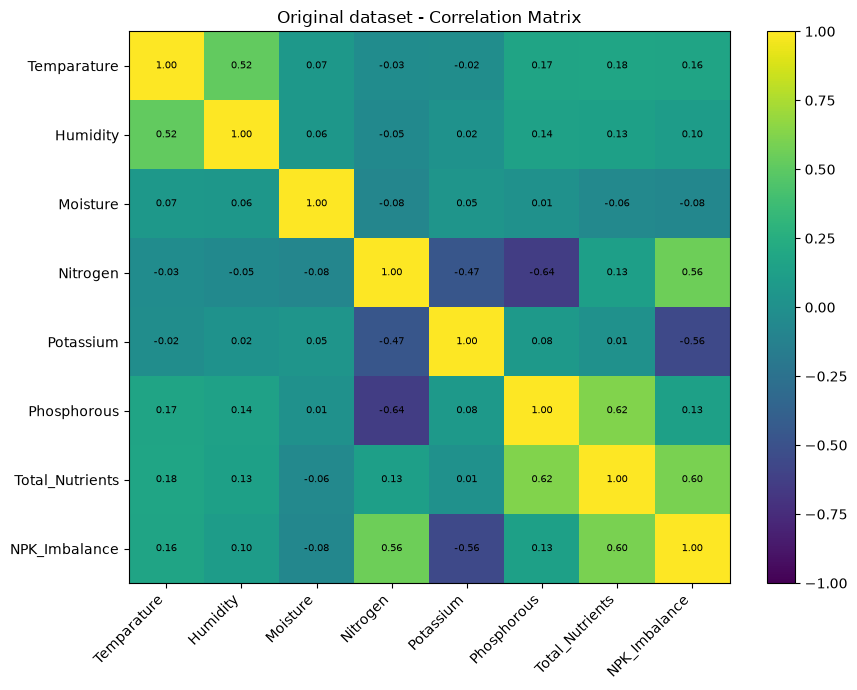

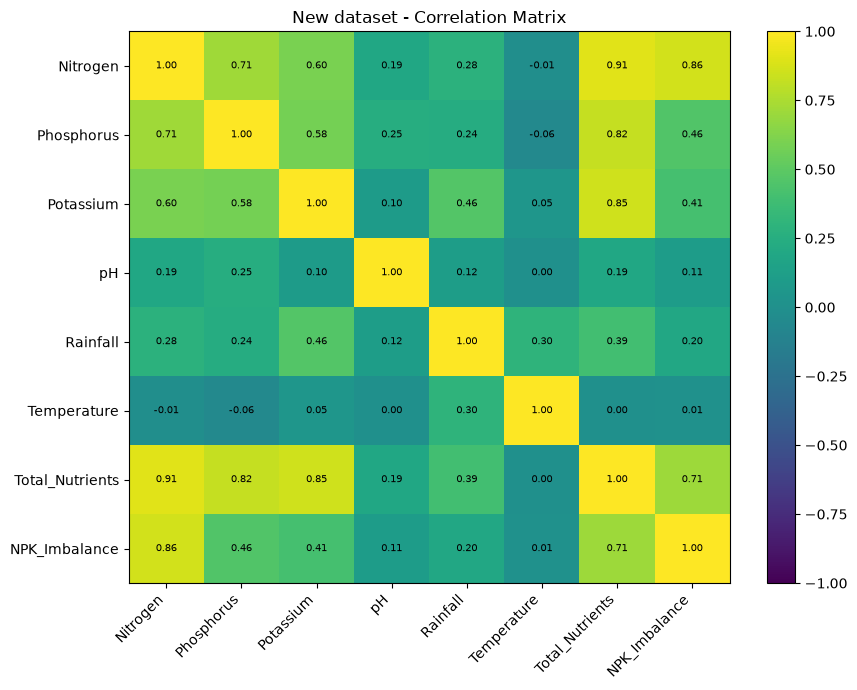

In [13]:
# correlation plots

for name, corr, out_dir in [
    ("Original dataset", original_corr, ORIGINAL_EDA_DIR),
    ("New dataset", new_corr, NEW_EDA_DIR),
]:
    fig, ax = plt.subplots(figsize=(9, 7))
    image = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)

    ax.set_xticks(range(len(corr.columns)))
    ax.set_yticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=45, ha="right")
    ax.set_yticklabels(corr.columns)
    ax.set_title(f"{name} - Correlation Matrix")

    for i in range(len(corr.columns)):
        for j in range(len(corr.columns)):
            ax.text(
                j,
                i,
                f"{corr.iloc[i, j]:.2f}",
                ha="center",
                va="center",
                fontsize=7
            )

    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    fig.savefig(out_dir / "correlation_matrix.png", dpi=150)
    plt.show()


In [14]:
# remove redundant feature

for frame in [
    X_train_original_work,
    X_test_original_work,
    X_train_new_work,
    X_test_new_work,
]:
    frame.drop(
        columns=["Total_Nutrients"],
        inplace=True,
        errors="ignore"
    )

print("Original:", X_train_original_work.shape)
print("New:", X_train_new_work.shape)


Original: (6400, 9)
New: (3610, 10)


In [15]:
# target encoding

original_label_encoder = LabelEncoder()
new_label_encoder = LabelEncoder()

y_train_original_encoded = original_label_encoder.fit_transform(
    y_train_original
)

y_test_original_encoded = original_label_encoder.transform(
    y_test_original
)

y_train_new_encoded = new_label_encoder.fit_transform(
    y_train_new
)

y_test_new_encoded = new_label_encoder.transform(
    y_test_new
)

original_mapping = pd.DataFrame({
    "Target_Label": range(len(original_label_encoder.classes_)),
    "Fertilizer": original_label_encoder.classes_
})

new_mapping = pd.DataFrame({
    "Target_Label": range(len(new_label_encoder.classes_)),
    "Fertilizer": new_label_encoder.classes_
})

original_mapping.to_csv(
    ORIGINAL_OUTPUT_DIR / "label_mapping.csv",
    index=False
)

new_mapping.to_csv(
    NEW_OUTPUT_DIR / "label_mapping.csv",
    index=False
)

print("Original target classes:", len(original_mapping))
print("New target classes:", len(new_mapping))


Original target classes: 7
New target classes: 19


In [16]:
# preprocessing setup

original_categorical = [
    "Soil Type",
    "Crop Type",
]

original_numeric_final = [
    "Temparature",
    "Humidity",
    "Moisture",
    "Nitrogen",
    "Potassium",
    "Phosphorous",
    "NPK_Imbalance",
]

new_categorical = [
    "District_Name",
    "Soil_color",
    "Crop",
]

new_numeric_final = [
    "Nitrogen",
    "Phosphorus",
    "Potassium",
    "pH",
    "Rainfall",
    "Temperature",
    "NPK_Imbalance",
]

def make_one_hot_encoder():
    try:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    except TypeError:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )

original_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            original_numeric_final
        ),
        (
            "categorical",
            make_one_hot_encoder(),
            original_categorical
        )
    ]
)

new_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            new_numeric_final
        ),
        (
            "categorical",
            make_one_hot_encoder(),
            new_categorical
        )
    ]
)


In [17]:
# fit preprocessing

X_train_original_processed = original_preprocessor.fit_transform(
    X_train_original_work
)

X_test_original_processed = original_preprocessor.transform(
    X_test_original_work
)

X_train_new_processed = new_preprocessor.fit_transform(
    X_train_new_work
)

X_test_new_processed = new_preprocessor.transform(
    X_test_new_work
)

original_feature_names = original_preprocessor.get_feature_names_out()
new_feature_names = new_preprocessor.get_feature_names_out()

print("Original processed train:", X_train_original_processed.shape)
print("Original processed test:", X_test_original_processed.shape)

print("\nNew processed train:", X_train_new_processed.shape)
print("New processed test:", X_test_new_processed.shape)


Original processed train: (6400, 23)
Original processed test: (1600, 23)

New processed train: (3610, 35)
New processed test: (903, 35)


In [18]:
# save processed data

train_original_processed_df = pd.DataFrame(
    X_train_original_processed,
    columns=original_feature_names
)

test_original_processed_df = pd.DataFrame(
    X_test_original_processed,
    columns=original_feature_names
)

train_new_processed_df = pd.DataFrame(
    X_train_new_processed,
    columns=new_feature_names
)

test_new_processed_df = pd.DataFrame(
    X_test_new_processed,
    columns=new_feature_names
)

train_original_processed_df["Target_Label"] = y_train_original_encoded
test_original_processed_df["Target_Label"] = y_test_original_encoded

train_new_processed_df["Target_Label"] = y_train_new_encoded
test_new_processed_df["Target_Label"] = y_test_new_encoded

train_original_processed_df.to_csv(
    ORIGINAL_OUTPUT_DIR / "train_processed.csv",
    index=False
)

test_original_processed_df.to_csv(
    ORIGINAL_OUTPUT_DIR / "test_processed.csv",
    index=False
)

train_new_processed_df.to_csv(
    NEW_OUTPUT_DIR / "train_processed.csv",
    index=False
)

test_new_processed_df.to_csv(
    NEW_OUTPUT_DIR / "test_processed.csv",
    index=False
)

print("Processed datasets saved.")


Processed datasets saved.


In [19]:
# final checks

for name, train_df, test_df in [
    (
        "Original dataset",
        train_original_processed_df,
        test_original_processed_df
    ),
    (
        "New dataset",
        train_new_processed_df,
        test_new_processed_df
    ),
]:
    print(f"\n{name}")
    print("Train:", train_df.shape)
    print("Test:", test_df.shape)
    print("Missing values:", train_df.isnull().sum().sum() + test_df.isnull().sum().sum())
    print("Train target classes:", train_df["Target_Label"].nunique())
    print("Test target classes:", test_df["Target_Label"].nunique())



Original dataset
Train: (6400, 24)
Test: (1600, 24)
Missing values: 0
Train target classes: 7
Test target classes: 7

New dataset
Train: (3610, 36)
Test: (903, 36)
Missing values: 0
Train target classes: 19
Test target classes: 19


## Outputs

- `results/outputs/original/train_processed.csv`
- `results/outputs/original/test_processed.csv`
- `results/outputs/original/label_mapping.csv`
- `results/outputs/original/outlier_summary.csv`
- `results/outputs/original/correlation_matrix.csv`
- `results/outputs/new/train_processed.csv`
- `results/outputs/new/test_processed.csv`
- `results/outputs/new/label_mapping.csv`
- `results/outputs/new/outlier_summary.csv`
- `results/outputs/new/correlation_matrix.csv`
